<a href="https://colab.research.google.com/github/zdiegomartins/Custotm_LLM/blob/main/Parte_1_Visualizando_Aten%C3%A7%C3%B5es.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#Rode só se precisar.
#%pip install -q -U transformers accelerate matplotlib seaborn

In [ ]:
import os
import getpass

hf_token = getpass.getpass('Token do Hugging Face: ')
os.environ['HF_TOKEN'] = hf_token

Token do Hugging Face: ··········


In [ ]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

MODEL_ID = "meta-llama/Llama-3.2-1B"
tokenizer = AutoTokenizer.from_pretrained(MODEL_ID, token=hf_token)
#Pode dar problema na T4. Se for o caso, troque bfloat16 para float16
model_dtype = torch.bfloat16 if torch.cuda.is_available() else torch.float32

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    token=hf_token,
    dtype=model_dtype,
    device_map="auto" if torch.cuda.is_available() else None,
    attn_implementation="eager", #sem isso pode não ser possível carregar as atenções
)
model.eval()
print("Modelo:", type(model).__name__)
print("Camadas:", model.config.num_hidden_layers)
print("Cabeças:", model.config.num_attention_heads)
print("Device:", model.get_input_embeddings().weight.device)

config.json:   0%|          | 0.00/843 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/50.5k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/301 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 2.47GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/185 [00:00<?, ?B/s]

Modelo: LlamaForCausalLM
Camadas: 16
Cabeças: 32
Device: cpu


In [ ]:
total_params = sum(p.numel() for p in model.parameters())
print(f"Parâmetros totais:      {total_params:,}")

Parâmetros totais:      1,235,814,400


In [ ]:
text = "The movie was surprisingly good!"
inputs = tokenizer(text, return_tensors="pt")
input_device = model.get_input_embeddings().weight.device
inputs = {name: tensor.to(input_device) for name, tensor in inputs.items()}
token_ids = inputs["input_ids"][0].tolist()
tokens = tokenizer.convert_ids_to_tokens(token_ids)
print("Texto:", text)
print("Quantidade de tokens:", len(tokens))
for i, token in enumerate(tokens):
    print(f"{i:2d}: {token!r}")
print("Texto reconstruído:", tokenizer.decode(token_ids))

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


Texto: The movie was surprisingly good!
Quantidade de tokens: 7
 0: '<|begin_of_text|>'
 1: 'The'
 2: 'Ġmovie'
 3: 'Ġwas'
 4: 'Ġsurprisingly'
 5: 'Ġgood'
 6: '!'
Texto reconstruído: <|begin_of_text|>The movie was surprisingly good!


In [ ]:
with torch.no_grad():
    outputs = model(**inputs, output_attentions=True, use_cache=False, return_dict=True)
attentions = outputs.attentions
if attentions is None or len(attentions) == 0:
    raise RuntimeError("Isso não deveria ter acontecido!")
print("Camadas com atenções:", len(attentions))
print("(batch, cabeças, tokens_query, tokens_key)")
print("Shape da primeira matriz:", tuple(attentions[0].shape))

Camadas com atenções: 16
(batch, cabeças, tokens_query, tokens_key)
Shape da primeira matriz: (1, 32, 7, 7)


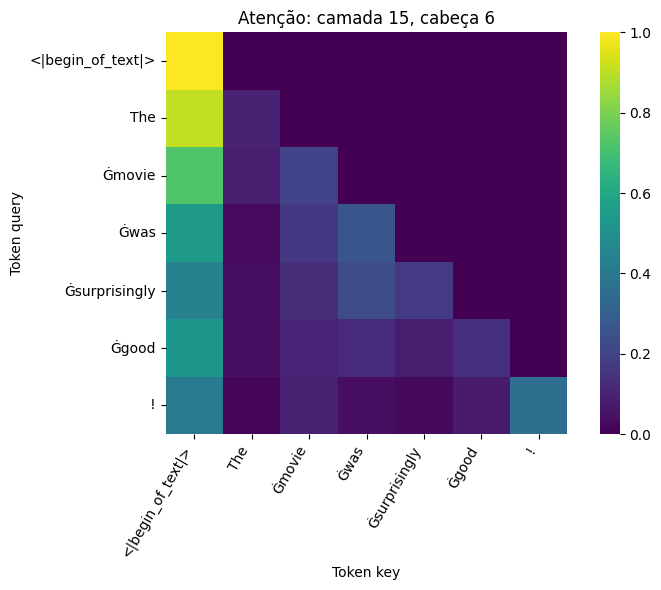

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

#Troque aqui os layers e os índices para recuperar outras cabeças de atenção
LAYER_INDEX = 15
HEAD_INDEX = 6
if not 0 <= LAYER_INDEX < len(attentions):
    raise ValueError(f"LAYER_INDEX deve estar entre 0 e {len(attentions)-1}.")
if not 0 <= HEAD_INDEX < attentions[LAYER_INDEX].shape[1]:
    raise ValueError(f"HEAD_INDEX deve estar entre 0 e {attentions[LAYER_INDEX].shape[1]-1}.")

attention = attentions[LAYER_INDEX][0, HEAD_INDEX].float().cpu().numpy()
plt.figure(figsize=(max(8, len(tokens)*0.7), max(6, len(tokens)*0.6)))
sns.heatmap(attention, xticklabels=tokens, yticklabels=tokens,
            cmap="viridis", vmin=0, vmax=1, square=True)
plt.title(f"Atenção: camada {LAYER_INDEX}, cabeça {HEAD_INDEX}")
plt.xlabel("Token key")
plt.ylabel("Token query")
plt.xticks(rotation=60, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

#Eixo vertical (query): token que distribui sua atenção. Eixo horizontal (key): token ao qual a atenção é direcionada.

In [ ]:
import numpy as np

attn = attentions[LAYER_INDEX][0, HEAD_INDEX].float().cpu().numpy()

print("Soma de cada linha:", np.round(attn.sum(axis=-1), 3))

print("Maior valor acima da diagonal:", np.triu(attn, k=1).max())

print("Tokens visíveis por linha:", (attn > 0).sum(axis=-1))

Soma de cada linha: [1.    1.    1.001 0.998 1.    1.001 1.   ]
Maior valor acima da diagonal: 0.0
Tokens visíveis por linha: [1 2 3 4 5 6 7]


In [ ]:
import ipywidgets as widgets
from ipywidgets import interact

n_layers = len(attentions)
n_heads = attentions[0].shape[1]
rotulos = [t.replace("Ġ", "") for t in tokens]   # remover o prefixo de espaço do Llama

def plot_attention(layer, head, media, vmax):
    if media:
        matrix = attentions[layer][0].float().mean(dim=0).cpu().numpy()
        titulo = f"Camada {layer}: média das {n_heads} cabeças"
    else:
        matrix = attentions[layer][0, head].float().cpu().numpy()
        titulo = f"Camada {layer}, cabeça {head}"

    plt.figure(figsize=(max(7, len(tokens)*0.7), max(5, len(tokens)*0.6)))
    sns.heatmap(matrix, xticklabels=rotulos, yticklabels=rotulos,
                cmap="viridis", vmin=0, vmax=vmax, square=True)
    plt.title(titulo)
    plt.xlabel("Token key")
    plt.ylabel("Token query")
    plt.xticks(rotation=60, ha="right")
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()

interact(
    plot_attention,
    layer=widgets.IntSlider(min=0, max=n_layers-1, value=15, description="Camada", continuous_update=False),
    head=widgets.IntSlider(min=0, max=n_heads-1, value=6, description="Cabeça", continuous_update=False),
    media=widgets.Checkbox(value=False, description="Média das cabeças"),
    vmax=widgets.FloatSlider(min=0.1, max=1.0, step=0.05, value=1.0, description="vmax", continuous_update=False),
);

interactive(children=(IntSlider(value=15, continuous_update=False, description='Camada', max=15), IntSlider(va…